In [2]:

# ============================================================
# NOTEBOOK 3: MACHINE LEARNING AND EVALUATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
OUT = "/content/Software-Quality-Insight"
PLOTS = f"{OUT}/visualizations"
PROCESSED = f"{OUT}/data/processed"

os.makedirs(PLOTS, exist_ok=True)
os.makedirs(PROCESSED, exist_ok=True)

uploaded = files.upload()
csv_file = next(
    (n for n in uploaded if n.lower().endswith(".csv")), None
)
if csv_file is None:
    raise ValueError("Upload software_quality_engineered.csv")

df = pd.read_csv(csv_file)

print("Dataset shape:", df.shape)
display(df.head())


Saving software_quality_engineered.csv to software_quality_engineered.csv
Dataset shape: (50, 21)


,module,release,complexity,coupling,churn,test_coverage,component,language,size,defect_count,...,commit_count,contributors,changed_lines,release_date,coverage_gap,churn_per_commit,changed_lines_per_commit,complexity_risk_band,module_total_defects,repeated_defect_concern
0,PAY,v1.0,31.0,0.58,181,0.57,Payment,Java,6100,10,...,30,5,238,2022-02-15,0.43,6.033333,7.933333,Very High,40,1
1,API,v1.0,28.0,0.55,161,0.50,API Gateway,Python,3500,9,...,27,5,218,2022-02-15,0.50,5.962963,8.074074,High,47,1
2,DB,v1.0,33.0,0.64,145,0.64,Database,Java,5200,8,...,24,4,198,2022-02-15,0.36,6.041667,8.250000,Very High,41,1
3,UI,v1.0,18.0,0.35,130,0.67,User Interface,TypeScript,4800,7,...,23,4,183,2022-02-15,0.33,5.652174,7.956522,Moderate,37,1
4,NOTIFY,v1.0,11.0,0.26,49,0.81,Notification,Python,2100,5,...,12,1,118,2022-02-15,0.19,4.083333,9.833333,Moderate,23,0


In [3]:

TARGET = "defect_count"

if TARGET not in df.columns:
    raise ValueError("The dataset must contain defect_count.")

# Use only information available when making the prediction.
# Exclude target-derived and historical summary fields to avoid leakage.
candidate_features = [
    "complexity",
    "coupling",
    "churn",
    "test_coverage",
    "size",
    "language",
    "component",
    "commit_count",
    "contributors",
    "changed_lines",
    "release"
]

features = [c for c in candidate_features if c in df.columns]

# Drop rows without a known target; do not treat missing target as zero.
model_df = df.dropna(subset=[TARGET]).copy()

X = model_df[features].copy()
y = pd.to_numeric(model_df[TARGET], errors="coerce")

valid = y.notna()
X = X.loc[valid].copy()
y = y.loc[valid].astype(float)

# Remove columns that have no usable values.
features = [
    c for c in X.columns
    if not X[c].isna().all()
]
X = X[features]

categorical_features = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numeric_features = [
    c for c in X.columns if c not in categorical_features
]

print("Target variable:", TARGET)
print("Selected features:", features)
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Usable records:", len(X))

if len(X) < 10:
    raise ValueError(
        "Too few usable records for this demonstration. "
        "Check the cleaned dataset before training."
    )


Target variable: defect_count
Selected features: ['complexity', 'coupling', 'churn', 'test_coverage', 'size', 'language', 'component', 'commit_count', 'contributors', 'changed_lines', 'release']
Numeric features: ['complexity', 'coupling', 'churn', 'test_coverage', 'size', 'commit_count', 'contributors', 'changed_lines']
Categorical features: ['language', 'component', 'release']
Usable records: 50


In [4]:

# Reproducible random holdout.
# Because this dataset has repeated modules across releases,
# this is an initial benchmark, not a strict future-release test.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

transformers = []
if numeric_features:
    transformers.append(
        ("numeric", numeric_pipeline, numeric_features)
    )
if categorical_features:
    transformers.append(
        ("categorical", categorical_pipeline, categorical_features)
    )

preprocessor = ColumnTransformer(transformers=transformers)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 40
Testing records: 10


In [5]:

models = {
    "Dummy Baseline": DummyRegressor(strategy="mean"),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

results = []
fitted_models = {}
predictions = {}

for name, estimator in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred) if len(y_test) > 1 else np.nan

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    fitted_models[name] = pipeline
    predictions[name] = pred

results_df = pd.DataFrame(results).sort_values("RMSE")
display(results_df)

results_df.to_csv(
    f"{PROCESSED}/model_performance.csv",
    index=False
)


,Model,MAE,RMSE,R2
1,Random Forest,1.665806,1.866281,0.331477
0,Dummy Baseline,1.900000,2.360085,-0.069098


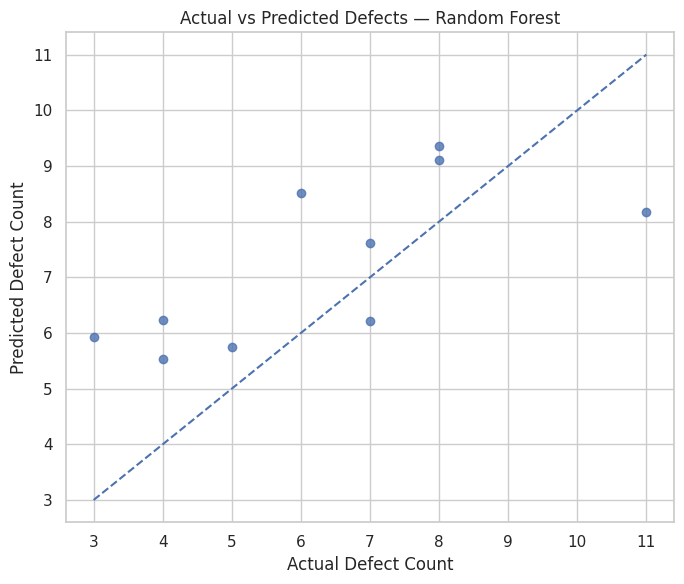

Best model by test RMSE: Random Forest


In [6]:

best_model_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]
best_predictions = predictions[best_model_name]

plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_predictions, alpha=0.8)

low = min(float(y_test.min()), float(best_predictions.min()))
high = max(float(y_test.max()), float(best_predictions.max()))
plt.plot([low, high], [low, high], linestyle="--")

plt.xlabel("Actual Defect Count")
plt.ylabel("Predicted Defect Count")
plt.title(f"Actual vs Predicted Defects — {best_model_name}")
plt.tight_layout()
plt.savefig(
    f"{PLOTS}/actual_vs_predicted.png",
    dpi=150
)
plt.show()

predictions_df = pd.DataFrame({
    "actual_defects": y_test.to_numpy(),
    "predicted_defects": best_predictions
})
predictions_df.to_csv(
    f"{PROCESSED}/model_predictions.csv",
    index=False
)

print("Best model by test RMSE:", best_model_name)


,feature,importance
5,numeric__commit_count,0.427250
1,numeric__coupling,0.139139
3,numeric__test_coverage,0.136377
0,numeric__complexity,0.065946
7,numeric__changed_lines,0.049218
6,numeric__contributors,0.038071
2,numeric__churn,0.031439
4,numeric__size,0.021430
23,categorical__release_v2.0,0.020050
16,categorical__component_File Service,0.012185


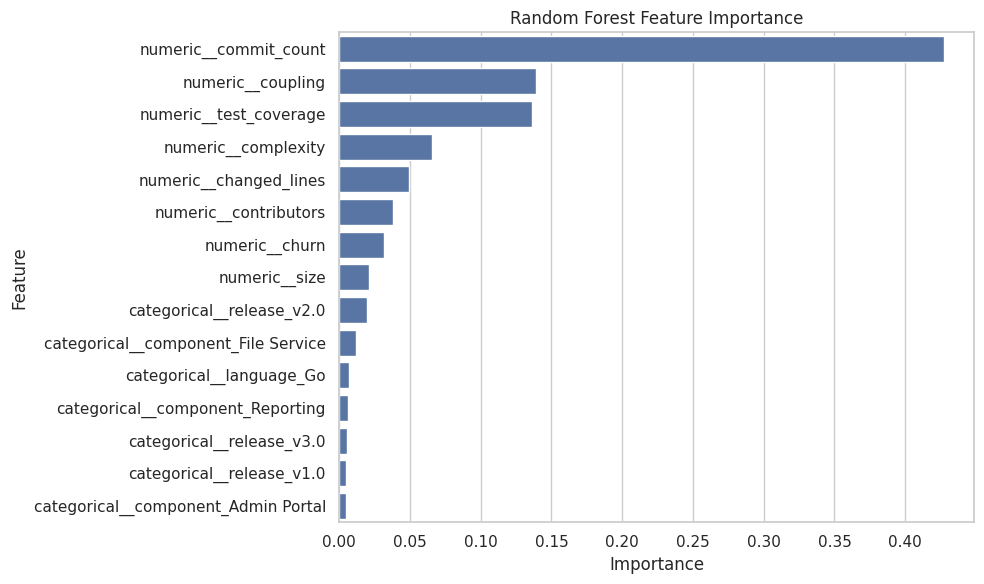

In [7]:

# Feature importance is available for the Random Forest model.
rf_pipeline = fitted_models["Random Forest"]
rf_model = rf_pipeline.named_steps["model"]
fitted_preprocessor = rf_pipeline.named_steps["preprocessor"]

try:
    transformed_names = fitted_preprocessor.get_feature_names_out()
    importances = rf_model.feature_importances_

    importance_df = pd.DataFrame({
        "feature": transformed_names,
        "importance": importances
    }).sort_values("importance", ascending=False)

    display(importance_df.head(15))

    plt.figure(figsize=(10, 6))
    sns.barplot(
        data=importance_df.head(15),
        x="importance",
        y="feature"
    )
    plt.title("Random Forest Feature Importance")
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.savefig(
        f"{PLOTS}/feature_importance.png",
        dpi=150
    )
    plt.show()

    importance_df.to_csv(
        f"{PROCESSED}/feature_importance.csv",
        index=False
    )

except Exception as error:
    print("Could not extract feature importance:", error)


In [8]:

best = results_df.sort_values("RMSE").iloc[0]
rf_result = results_df[results_df["Model"] == "Random Forest"].iloc[0]

print("=" * 55)
print("SOFTWARE QUALITY INSIGHT: MODEL RESULTS")
print("=" * 55)

print("Target:", TARGET)
print("Selected input features:", ", ".join(features))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nRandom Forest results:")
print(f"MAE  : {rf_result['MAE']:.3f}")
print(f"RMSE : {rf_result['RMSE']:.3f}")
print(f"R²   : {rf_result['R2']:.3f}")

print("\nBest model by RMSE:", best["Model"])
print(f"Best test RMSE: {best['RMSE']:.3f}")

print("\nInterpretation:")
print("- MAE is the average absolute prediction error in defect-count units.")
print("- RMSE penalizes larger prediction errors more heavily.")
print("- R² measures test-set fit; a negative value means worse performance")
print("  than predicting the test-set mean under the usual R² definition.")
print("- Feature importance describes model reliance, not causation.")

results_dict = {
    "target": TARGET,
    "features": features,
    "training_records": int(len(X_train)),
    "testing_records": int(len(X_test)),
    "best_model_by_rmse": str(best["Model"]),
    "models": results_df.to_dict(orient="records")
}

with open(
    f"{PROCESSED}/model_results.json", "w"
) as f:
    json.dump(results_dict, f, indent=2, default=str)

files.download(f"{PROCESSED}/model_performance.csv")


SOFTWARE QUALITY INSIGHT: MODEL RESULTS
Target: defect_count
Selected input features: complexity, coupling, churn, test_coverage, size, language, component, commit_count, contributors, changed_lines, release
Training records: 40
Testing records: 10

Random Forest results:
MAE  : 1.666
RMSE : 1.866
R²   : 0.331

Best model by RMSE: Random Forest
Best test RMSE: 1.866

Interpretation:
- MAE is the average absolute prediction error in defect-count units.
- RMSE penalizes larger prediction errors more heavily.
- R² measures test-set fit; a negative value means worse performance
  than predicting the test-set mean under the usual R² definition.
- Feature importance describes model reliance, not causation.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>